In [41]:


# Execute this first 
#
#  * trigger notebook styling
#  * check if notebook had been modified since its distribution
# 
# Note: executing any cells before this modifies the notebook.
# 

import os

# Add Homebrew's bin folder to the system path used by Jupyter
os.environ['PATH'] += ":/opt/homebrew/bin"

# Test if it works now
!gmx -version

#check_notebook()

                     :-) GROMACS - gmx, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx -version

GROMACS version:     2025.4-Homebrew
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         disabled
SIMD instructions:   ARM_NEON_ASIMD
CPU FFT library:     fftw-3.3.10
GPU FFT library:     none
Multi-GPU FFT:       none
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
C compiler:          /opt/homebrew/opt/gcc/bin/gcc-15
C compiler flags:    -fexcess-precision=fast -funroll-all-loops -Wno-missing-field-initializers -O3 -DNDEBUG
C++ compiler:        /opt/homebrew/opt/gcc/bin/g++-15
C++ compiler flags:  -fexcess-precision=fast -funroll

In [42]:
%pip install nglview pandas mdtraj numpy matplotlib
import nglview as ng
import pandas as pd
import mdtraj as md
import numpy as np
import matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/Cellar/jupyterlab/4.5.2/libexec/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [43]:
%cd ~/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
!ls

/Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
#dos.log.1#       #nvt.edr.1#       md.cpt            npt2.gro
#em.edr.1#        #nvt.log.1#       md.edr            npt2.log
#em.gro.1#        #nvt.tpr.1#       md.gro            npt2.tpr
#em.log.1#        #nvt.trr.1#       md.log            npt2.trr
#em.tpr.1#        #potential.xvg.1# md.tpr            nvt_prev.cpt
#em.trr.1#        #potential.xvg.2# md.trr            nvt.cpt
#md.edr.1#        #potential.xvg.3# mdout.mdp         nvt.edr
#md.log.1#        box.gro           methane_bonds.py  nvt.gro
#md.tpr.1#        convert_dos.py    methane.gro       nvt.log
#md.trr.1#        density1.xvg      methane.pdb       nvt.mdp
#npt1.edr.1#      density2.xvg      Methane94K.ipynb  nvt.tpr
#npt1.edr.2#      dos.log           methaneDOS.py     nvt.trr
#npt1.edr.3#      DOS.py            mvacf.xvg         OLD_methaneDOS.py
#npt1.gro.1#      dos.xvg           npt.mdp           peaks.py
#npt1.log.1#      em.edr         

In [44]:
# Load and view the .pdb or .gro file with the following lines
view = ng.show_structure_file("methane.pdb")
view

NGLWidget()

In [45]:
# Create larger box to grow simulation
!gmx editconf -f methane.pdb -o box.gro -box 2.8 2.8 2.8 -noc

# Add the Methane Molecules to the larger box
!gmx insert-molecules -ci methane.pdb -nmol 200 -box 2.8 2.8 2.8 -o methane.gro -seed 12345 -try 10000

                :-) GROMACS - gmx editconf, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx editconf -f methane.pdb -o box.gro -box 2.8 2.8 2.8 -noc

Note that major changes are planned in future for editconf, to improve usability and utility.
Read 5 atoms
No velocities found
new box vectors :  2.800  2.800  2.800 (nm)
new box angles  :  90.00  90.00  90.00 (degrees)
new box volume  :  21.95               (nm^3)

Back Off! I just backed up box.gro to ./#box.gro.1#

GROMACS reminds you: "It is not critical to add the next quote to a patch release" (Paul Bauer)

            :-) GROMACS - gmx insert-molecules, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenl

In [46]:
# View the system
view = ng.show_structure_file("methane.gro")
view.add_representation(repr_type='ball+stick', selection='SOL')
view.camera='orthographic'
view

NGLWidget()

In [47]:
#Energy Minimization
!gmx grompp -f em.mdp -c methane.gro -p topol.top -o em.tpr -maxwarn 1
!gmx mdrun -deffnm em -ntmpi 1 -ntomp 1

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx grompp -f em.mdp -c methane.gro -p topol.top -o em.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to -536881217

Generated 330891 of the 330891 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 330891 of the 330891 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'CD4'

atom name 1 in topol.top and methane.gro does not match (C - C1)
atom name 1 in topol.top and methane.gro does not match (C - C1)

atom name 6 in topol.top and methane.gro does not match (C - C1)

atom name 6 in topol.top and methane.gro does not match (C - C1)

atom name 11 in topol.top and methane.gro does not match (C - C1)

atom na

In [13]:
#Analyze results of EM
!printf "Potential\n0\n" | gmx energy -f em.edr -o potential.xvg -xvg none

                 :-) GROMACS - gmx energy, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx energy -f em.edr -o potential.xvg -xvg none

Opened em.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  LJ-(SR)          4  Disper.-corr. 
  5  Coulomb-(SR)     6  Coul.-recip.     7  Potential        8  Pres.-DC      
  9  Pressure        10  Vir-XX          11  Vir-XY          12  Vir-XZ        
 13  Vir-YX          14  Vir-YY          15  Vir-YZ          16  Vir-ZX        
 17  Vir-ZY          18  Vir-ZZ          19  Pres-X

<Axes: xlabel='step'>

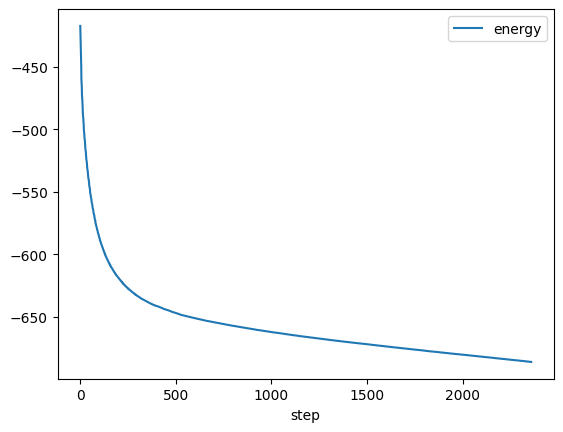

In [48]:
# Print graph
df = pd.read_csv('potential.xvg', sep='\\s+', header=None, names=['step','energy'])
df.plot('step')

In [49]:
# Temperature EQ T=94K
!gmx grompp -f nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr 
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm nvt

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx grompp -f nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr

Setting the LD random seed to -50884869

Generated 330891 of the 330891 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 330891 of the 330891 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'CD4'

turning H bonds into constraints...

Setting gen_seed to -270532873

Velocities were taken from a Maxwell distribution at 150 K

NOTE 1 [file topol.top, line 48]:
  The bond in molecule-type CD4 between atoms 1 C and 2 D1 has an estimated
  oscillational period of 1.5e-02 ps, which is less than 10 times the time
  step of 2.0e-03 ps.
  Maybe you forgot to change the constraints

In [50]:
# Analyze Temp run
!echo "Temperature" | gmx energy -f nvt.edr -o temperature.xvg -xvg none -b 20

                 :-) GROMACS - gmx energy, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx energy -f nvt.edr -o temperature.xvg -xvg none -b 20

Opened nvt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  LJ-(SR)          4  Disper.-corr. 
  5  Coulomb-(SR)     6  Coul.-recip.     7  Potential        8  Kinetic-En.   
  9  Total-Energy    10  Conserved-En.   11  Temperature     12  Pres.-DC      
 13  Pressure        14  Vir-XX          15  Vir-XY          16  Vir-XZ        
 17  Vir-YX          18  Vir-YY          

<Axes: xlabel='time'>

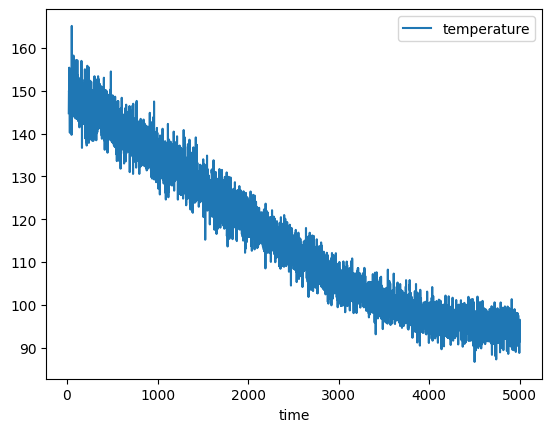

In [51]:
# Plot Temp data
df = pd.read_csv('temperature.xvg', sep='\\s+', header=None, names=['time','temperature'])
df.plot('time')
#!echo "Temperature" | gmx energy -f nvt.edr -o temperature.xvg -b 20
#!xmgrace temperature.xvg

In [60]:
# Pressure EQ P = 1.5 bars
!gmx grompp -f npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt1.tpr -maxwarn 1
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm npt1

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx grompp -f npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt1.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'

WARNING 1 [file npt.mdp]:
  The Berendsen barostat does not generate any strictly correct ensemble,
  and should not be used for new production simulations (in our opinion).
  We recommend using the C-rescale barostat instead.

Setting the LD random seed to 266362847

Generated 330891 of the 330891 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 330891 of the 330891 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'CD4'

turning all bonds into constraints...

NOTE 1 [file unknown]:
  You are using constraint

In [61]:
# Analyze Pressure Data
!echo "Pressure" | gmx energy -f npt1.edr -o pressure.xvg -xvg none

                 :-) GROMACS - gmx energy, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx energy -f npt1.edr -o pressure.xvg -xvg none

Opened npt1.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Angle            2  LJ-(SR)          3  Disper.-corr.    4  Coulomb-(SR)  
  5  Coul.-recip.     6  Potential        7  Kinetic-En.      8  Total-Energy  
  9  Conserved-En.   10  Temperature     11  Pres.-DC        12  Pressure      
 13  Constr.-rmsd    14  Box-X           15  Box-Y           16  Box-Z         
 17  Volume          18  Density         19  pV 

<Axes: xlabel='time'>

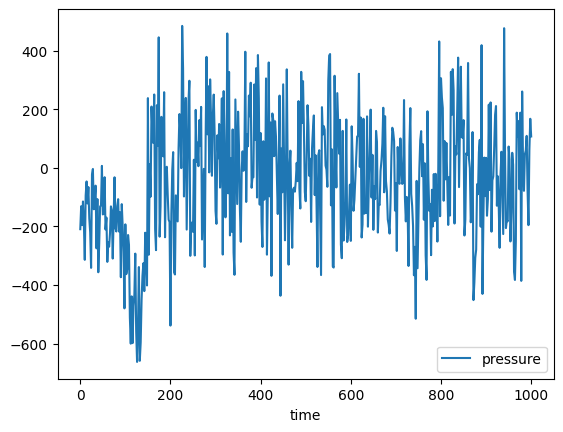

In [24]:
df = pd.read_csv('pressure.xvg', sep='\\s+', header=None, names=['time','pressure'])
df.plot('time')

In [ ]:
#!echo "Pressure" | gmx energy -f npt.edr -o pressure.xvg
#!xmgrace pressure.xvg

In [62]:
# Look at density of system
!echo "Density" | gmx energy -f npt1.edr -o density1.xvg -xvg none

                 :-) GROMACS - gmx energy, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx energy -f npt1.edr -o density1.xvg -xvg none

Opened npt1.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Angle            2  LJ-(SR)          3  Disper.-corr.    4  Coulomb-(SR)  
  5  Coul.-recip.     6  Potential        7  Kinetic-En.      8  Total-Energy  
  9  Conserved-En.   10  Temperature     11  Pres.-DC        12  Pressure      
 13  Constr.-rmsd    14  Box-X           15  Box-Y           16  Box-Z         
 17  Volume          18  Density         19  pV 

<Axes: xlabel='time'>

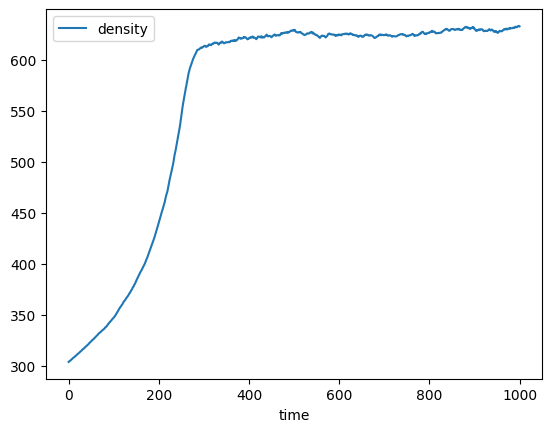

In [63]:
#Plot density
df = pd.read_csv('density1.xvg', sep='\\s+', header=None, names=['time','density'])
df.plot('time')

In [64]:
!tail -1 npt1.gro

   2.19164   2.19164   2.19164


In [39]:
#!gmx editconf -f npt1.gro -o npt1_expanded.gro -box 2.2 2.2 2.2 -c

In [65]:
# Pressure EQ Stage 2
!gmx grompp -f npt.mdp -c npt1.gro -t npt1.cpt -p topol.top -o npt2.tpr -maxwarn 1
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm npt2

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx grompp -f npt.mdp -c npt1.gro -t npt1.cpt -p topol.top -o npt2.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'

WARNING 1 [file npt.mdp]:
  The Berendsen barostat does not generate any strictly correct ensemble,
  and should not be used for new production simulations (in our opinion).
  We recommend using the C-rescale barostat instead.

Setting the LD random seed to -46138953

Generated 330891 of the 330891 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 330891 of the 330891 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'CD4'

turning all bonds into constraints...

NOTE 1 [file unknown]:
  You are using constraints on all 

                 :-) GROMACS - gmx energy, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx energy -f npt2.edr -o pressure2.xvg -xvg none

Opened npt2.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Angle            2  LJ-(SR)          3  Disper.-corr.    4  Coulomb-(SR)  
  5  Coul.-recip.     6  Potential        7  Kinetic-En.      8  Total-Energy  
  9  Conserved-En.   10  Temperature     11  Pres.-DC        12  Pressure      
 13  Constr.-rmsd    14  Box-X           15  Box-Y           16  Box-Z         
 17  Volume          18  Density         19  pV

<Axes: xlabel='time'>

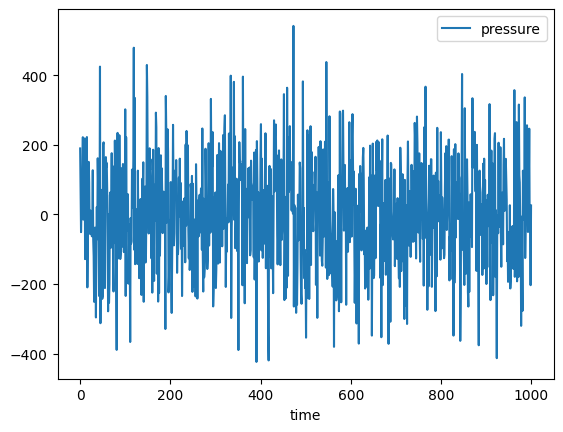

In [66]:
# Analyze Pressure Data
!echo "Pressure" | gmx energy -f npt2.edr -o pressure2.xvg -xvg none

df = pd.read_csv('pressure2.xvg', sep='\\s+', header=None, names=['time','pressure'])
df.plot('time')

                 :-) GROMACS - gmx energy, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx energy -f npt2.edr -o density2.xvg -xvg none

Opened npt2.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Angle            2  LJ-(SR)          3  Disper.-corr.    4  Coulomb-(SR)  
  5  Coul.-recip.     6  Potential        7  Kinetic-En.      8  Total-Energy  
  9  Conserved-En.   10  Temperature     11  Pres.-DC        12  Pressure      
 13  Constr.-rmsd    14  Box-X           15  Box-Y           16  Box-Z         
 17  Volume          18  Density         19  pV 

<Axes: xlabel='time'>

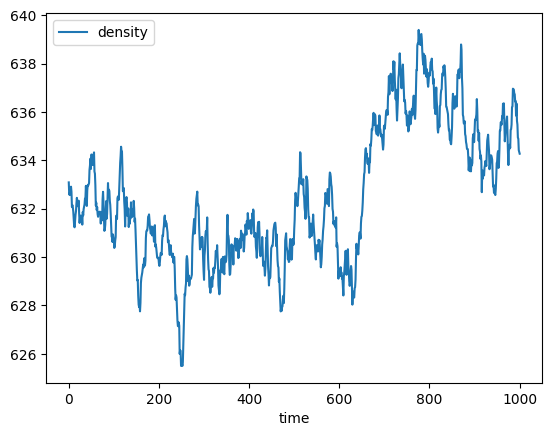

In [67]:
# Look at density of system
!echo "Density" | gmx energy -f npt2.edr -o density2.xvg -xvg none

#Plot density
df = pd.read_csv('density2.xvg', sep='\\s+', header=None, names=['time','density'])
df.plot('time')

In [68]:
#Production Run
!gmx grompp -f production.mdp -c npt1.gro -t npt1.cpt -p topol.top -o md.tpr -maxwarn 1
!gmx mdrun -ntmpi 1 -ntomp 8 -pin on -v -deffnm md

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx grompp -f production.mdp -c npt1.gro -t npt1.cpt -p topol.top -o md.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to -8929345

Generated 330891 of the 330891 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 330891 of the 330891 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'CD4'

Taking velocities from 'npt1.gro'

NOTE 1 [file topol.top, line 48]:
  The bond in molecule-type CD4 between atoms 1 C and 2 D1 has an estimated
  oscillational period of 1.5e-02 ps, which is less than 10 times the time
  step of 2.0e-03 ps.
  Maybe you forgot to change the constraints mdp option.

Analysing residue name

In [69]:
import os
print("md.trr exists:", os.path.exists("md.trr"))
print("methane.gro exists:", os.path.exists("methane.gro"))

md.trr exists: True
methane.gro exists: True


In [33]:
import mdtraj as md
import os

# Check files exist
print("md.trr exists:", os.path.exists("md.trr"))
print("methane.gro exists:", os.path.exists("methane.gro"))

# Load and check trajectory
try:
    traj = md.load_trr("md.trr", top="methane.gro", stride=10)
    print(f"Loaded trajectory: {traj.n_frames} frames, {traj.n_atoms} atoms")
    print(f"Time range: {traj.time[0]:.1f} to {traj.time[-1]:.1f} ps")
    
    # Try creating view
    view = ng.show_mdtraj(traj)
    print(f"View created: {type(view)}")
    
    # Display
    view
except Exception as e:
    print(f"Error: {e}")

md.trr exists: True
methane.gro exists: True
Loaded trajectory: 50001 frames, 1000 atoms
Time range: 0.0 to 1000.0 ps
View created: <class 'nglview.widget.NGLWidget'>


In [34]:
import nglview as ng
import mdtraj as md

# Enable widget rendering
ng.default_view_backend = 'notebook'  # or 'ipywidgets'
# Load trajectory
traj = md.load_trr("md.trr", top="md.gro")
view = ng.show_mdtraj(traj)
# Display
view

NGLWidget(max_frame=500000)

In [77]:
%%writefile production.mdp
; Methane under Titan conditions - Production for Density of States
integrator      = md
dt              = 0.001      ; 1 fs (Small enough for flexible C-D bonds)
nsteps          = 50000      ; 50 ps total 
nstxout         = 0          ; Don't save coordinates 
nstvout         = 1          ; Save velocities EVERY step (Crucial for VDOS)
nstenergy       = 500        ; Save energies every 0.5 ps
nstlog          = 500        ; Update log file every 0.5 ps

cutoff-scheme   = Verlet
ns_type         = grid
nstlist         = 10         
rlist           = 0.85
rcoulomb        = 0.85
rvdw            = 0.85

coulombtype     = PME
pme_order       = 4
fourierspacing  = 0.16

tcoupl          = V-rescale
tc-grps         = System
tau_t           = 0.1
ref_t           = 94         

pcoupl          = C-rescale
pcoupltype      = isotropic
tau_p           = 5.0
ref_p           = 1.5        
compressibility = 4.5e-5

constraints     = none       ; ABSOLUTELY MUST BE NONE FOR VIBRATIONS
constraint_algorithm = lincs
lincs_iter      = 1
lincs_order     = 4

DispCorr        = EnerPres
pbc             = xyz
gen_vel         = no

Overwriting production.mdp


In [78]:
# 1. Recompile the flexible, high-sampling production run
!gmx grompp -f production.mdp -c npt1.gro -t npt1.cpt -p topol.top -o md.tpr -maxwarn 1

# 2. Run the MD simulation 
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm md

# 3. Recalculate the DOS
!echo "2" | gmx dos -f md.trr -s md.tpr -dos dos.xvg -vacf vacf.xvg

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/Programming/DraGNS/Repo_Full/Methane/94K/BaseFiles_Drun
Command line:
  gmx grompp -f production.mdp -c npt1.gro -t npt1.cpt -p topol.top -o md.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to -539038773

Generated 330891 of the 330891 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 330891 of the 330891 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'CD4'

Taking velocities from 'npt1.gro'
Analysing residue names:
There are:   200      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group System is 2997.00

The largest distance between excluded atoms is 0.187 nm between atom

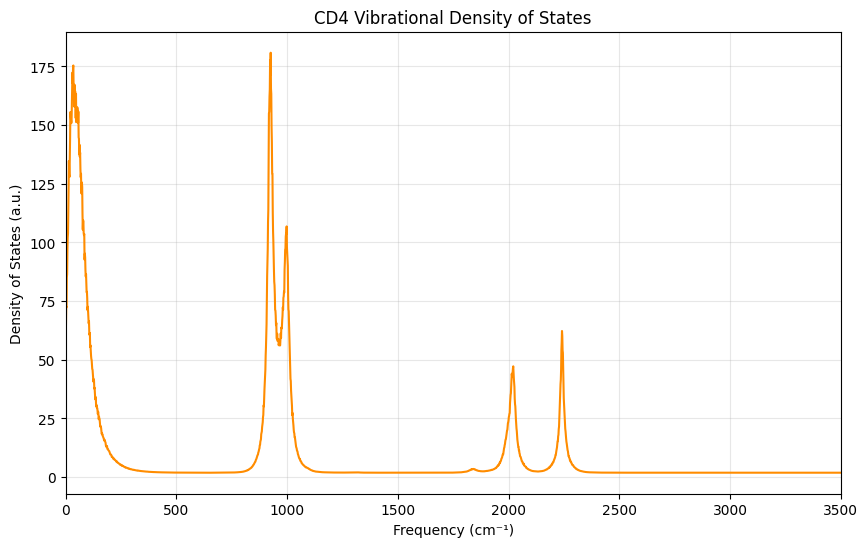

In [80]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter out metadata headers and grab ONLY the first two columns
with open('dos.xvg', 'r') as f:
    lines = [line.split()[:2] for line in f if not line.startswith(('@', '#'))]

# Load into dataframe
df_dos = pd.DataFrame(lines, columns=['Frequency_THz', 'DOS'], dtype=float)

# CONVERSION: 1 ps^-1 (THz) = 33.35641 cm^-1
df_dos['Frequency_cm-1'] = df_dos['Frequency_THz'] * 33.35641

plt.figure(figsize=(10, 6))
# Plot using the new converted wavenumber column
plt.plot(df_dos['Frequency_cm-1'], df_dos['DOS'], color='darkorange')
plt.title('CD4 Vibrational Density of States')
plt.xlabel('Frequency (cm⁻¹)')
plt.ylabel('Density of States (a.u.)')
plt.xlim(0, 3500)
plt.grid(alpha=0.3)
plt.show()